# 은행 마케팅 고객의 정기 예금 가입 예측
홍화령 | Python 분류 모델링 개인 프로젝트

가입자가 11.7%인 불균형 데이터에서 전체 정확도를 유지하면서 가입자 예측 성능을 개선한다. EDA에서 확인한 고객 특성과 연락 이력을 입력 변수에 반영하고, 모델과 임계값을 비교한다.

## 평가 기준
- 기본 목표: Accuracy 80% 이상, 가입자 F1 40% 이상
- 심화 목표: Accuracy 88% 이상, 가입자 F1 45% 이상
- 가입자 F1과 함께 비가입자 F1도 확인한다.

## 실행 방법
저장소의 루트 폴더에서 노트북을 실행한다. 원본 `bank_marketing.csv`를 `data/bank_marketing.csv`에 넣고, 위에서부터 모든 셀을 실행한다. 필요 패키지는 `requirements.txt`를 참고한다. 결과표는 마지막 셀에서 `results/`에 저장한다.

## 분석 흐름
데이터 확인 → 베이스라인 → 학습 데이터 EDA → 피처 엔지니어링 → 모델 비교 → 가중치 및 임계값 조정 → 최종 검증

데이터와 기초 로지스틱 회귀 설정은 코드잇 스프린트 미션 12에서 제공된 자료를 바탕으로 한다.

## 1. 라이브러리와 데이터 불러오기

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

plt.rcParams['figure.figsize'] = (8, 4)
data_path = Path('data') / 'bank_marketing.csv'
df = pd.read_csv(data_path)
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,no


In [2]:
print('데이터 크기:', df.shape)
print('결측값 수:', df.isna().sum().sum())
print('완전히 같은 행 수:', df.duplicated().sum())
print(df.dtypes)
print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True).round(4))

데이터 크기: (45211, 16)
결측값 수: 0
완전히 같은 행 수: 16
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object
y
no     39922
yes     5289
Name: count, dtype: int64
y
no     0.883
yes    0.117
Name: proportion, dtype: float64


데이터는 45,211행, 16열이고 실제 결측값은 없다. `unknown`은 문자열로 들어 있는 미상 범주이므로 그대로 둔다. 가입자는 5,289명(11.70%), 비가입자는 39,922명(88.30%)이다. 모두 비가입자로 예측해도 정확도가 약 88.3%이므로 정확도만으로 평가하면 안 된다.

## 2. 베이스라인 확인

In [3]:
y = (df['y'] == 'yes').astype(int)
X = pd.get_dummies(df.drop(columns='y'), drop_first=True)

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print(X_train.shape, X_valid.shape)
print('학습 가입자 비율:', y_train.mean())
print('검증 가입자 비율:', y_valid.mean())

(31647, 41) (13564, 41)
학습 가입자 비율: 0.11697791259835055
검증 가입자 비율: 0.1170008846947803


In [4]:
baseline_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_valid)
print(classification_report(y_valid, baseline_pred, target_names=['비가입자', '가입자']))

              precision    recall  f1-score   support

        비가입자       0.90      0.99      0.94     11977
         가입자       0.68      0.18      0.29      1587

    accuracy                           0.89     13564
   macro avg       0.79      0.59      0.62     13564
weighted avg       0.88      0.89      0.87     13564



In [5]:
def evaluate(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        '비가입자 F1': f1_score(y_true, y_pred, pos_label=0),
        '가입자 F1': f1_score(y_true, y_pred, pos_label=1)
    }

baseline_scores = evaluate(y_valid, baseline_pred)
print(pd.Series(baseline_scores).round(4))
print('모두 비가입자라고 예측한 정확도:', (y_valid == 0).mean())

Accuracy    0.8944
비가입자 F1     0.9430
가입자 F1      0.2897
dtype: float64
모두 비가입자라고 예측한 정확도: 0.8829991153052197


베이스라인의 Accuracy는 **89.44%**, 가입자 F1은 **28.97%**이다. 비가입자를 주로 맞히면서 전체 정확도는 높지만 가입자 예측 성능은 목표에 미치지 못한다.

정밀도는 가입자로 예측한 사람 중 실제 가입한 비율, 재현율은 실제 가입자 중 찾아낸 비율이다. F1은 이 둘의 조화평균이다.

## 3. 탐색적 데이터 분석
피처 설계에 검증 데이터의 정답을 이용하지 않도록 아래 패턴은 학습 데이터에서 확인한다. 그래프는 실행 환경의 한글 폰트와 관계없이 보이도록 영어 축을 사용한다.

,count,mean
age_group,,
under30,3770,0.1785
30s,12626,0.1058
40s,8198,0.0928
50s,5795,0.0892
60plus,1258,0.3299


,count,mean
job,,
blue-collar,6866,0.0715
housemaid,893,0.0817
entrepreneur,1044,0.0881
services,2879,0.0914
technician,5306,0.1078
self-employed,1076,0.1097
admin.,3662,0.1234
unknown,206,0.1311
management,6530,0.1409


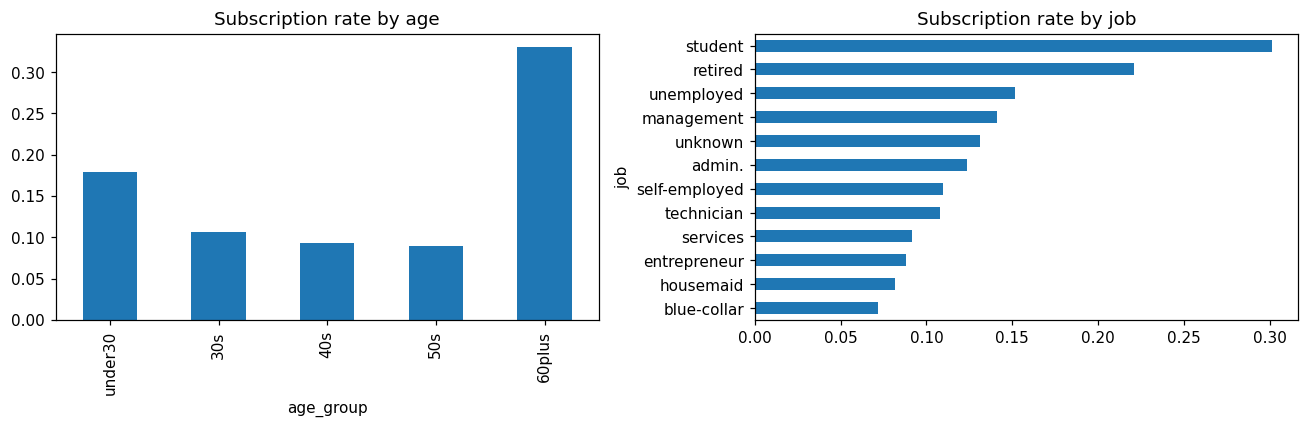

In [6]:
eda = df.loc[X_train.index].copy()
eda['y'] = y_train
eda['age_group'] = pd.cut(
    eda['age'], bins=[0, 29, 39, 49, 59, 100],
    labels=['under30', '30s', '40s', '50s', '60plus']
)

age_table = eda.groupby('age_group', observed=True)['y'].agg(['count', 'mean'])
job_table = eda.groupby('job')['y'].agg(['count', 'mean']).sort_values('mean')
display(age_table.round(4), job_table.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
age_table['mean'].plot(kind='bar', ax=axes[0], title='Subscription rate by age')
job_table['mean'].plot(kind='barh', ax=axes[1], title='Subscription rate by job')
plt.tight_layout()
plt.show()

**패턴 1.** 60세 이상 가입률은 32.99%, 30대는 10.58%로 나이에 따른 차이가 있다. 직업별로는 학생 30.13%, 은퇴자 22.08%로 높고 현장 근로자는 7.15%로 낮다. → 나이의 구간별 차이를 표현할 `age_group`을 추가한다.

marital


,count,mean
marital,,
divorced,3632,0.1231
married,19049,0.0996
single,8966,0.1515


education


,count,mean
education,,
primary,4885,0.0847
secondary,16201,0.1067
tertiary,9247,0.1502
unknown,1314,0.1301


default


,count,mean
default,,
no,31083,0.1181
yes,564,0.0567


housing


,count,mean
housing,,
no,14022,0.1662
yes,17625,0.0778


loan


,count,mean
loan,,
no,26573,0.1261
yes,5074,0.0692


,median,mean,min,max
y,,,,
0,419.0,1300.58,-8019,102127
1,752.0,1839.22,-1944,81204


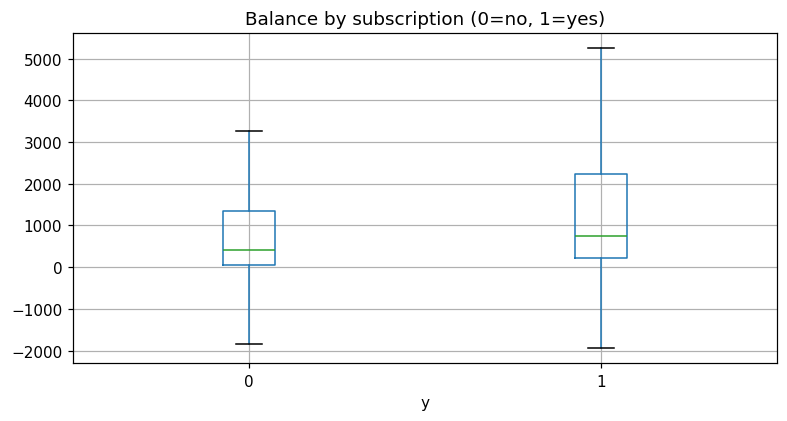

In [7]:
for col in ['marital', 'education', 'default', 'housing', 'loan']:
    print(col)
    display(eda.groupby(col)['y'].agg(['count', 'mean']).round(4))

display(eda.groupby('y')['balance'].agg(['median', 'mean', 'min', 'max']).round(2))
eda.boxplot(column='balance', by='y', showfliers=False)
plt.title('Balance by subscription (0=no, 1=yes)')
plt.suptitle('')
plt.show()

**패턴 2.** 주택 대출이 없는 고객의 가입률은 16.62%, 있는 고객은 7.78%이다. 개인 대출도 없을 때 12.61%, 있을 때 6.92%이다. 대출 여부는 기존 입력 변수로 유지한다.

잔고에는 음수가 있고 큰 양수도 존재한다. 단순히 이상치로 삭제하지 않고, 부호를 유지한 로그 변환으로 값의 크기 차이를 줄여 본다. 변환의 효과는 모델 비교로 확인한다.

poutcome


,count,mean
poutcome,,
failure,3378,0.1246
other,1301,0.1622
success,1051,0.6375
unknown,25917,0.0926


prev_contacted


,count,mean
prev_contacted,,
0,25912,0.0925
1,5735,0.2274


campaign_group


,count,mean
campaign_group,,
once,12294,0.1454
two_three,12628,0.1128
four_plus,6725,0.0729


contact


,count,mean
contact,,
cellular,20517,0.1489
telephone,2030,0.1360
unknown,9100,0.0407


,count,mean
month,,
jan,986,0.1045
feb,1829,0.1711
mar,337,0.5104
apr,2081,0.1932
may,9643,0.0657
jun,3725,0.1042
jul,4846,0.0935
aug,4355,0.1098
sep,386,0.4508


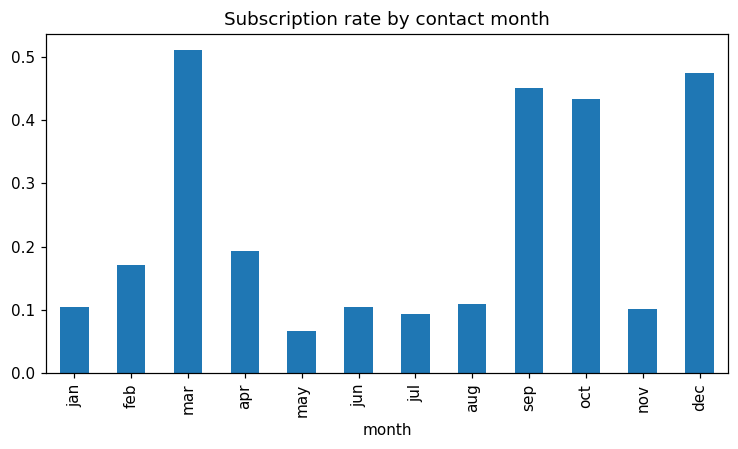

In [8]:
eda['prev_contacted'] = (eda['pdays'] != -1).astype(int)
eda['campaign_group'] = pd.cut(
    eda['campaign'], bins=[0, 1, 3, 100],
    labels=['once', 'two_three', 'four_plus']
)
for col in ['poutcome', 'prev_contacted', 'campaign_group', 'contact']:
    print(col)
    display(eda.groupby(col, observed=True)['y'].agg(['count', 'mean']).round(4))

month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
month_table = eda.groupby('month')['y'].agg(['count', 'mean']).reindex(month_order)
display(month_table.round(4))
month_table['mean'].plot(kind='bar', title='Subscription rate by contact month')
plt.show()

**패턴 3.** 이전 캠페인 성공 고객의 가입률은 63.75%, 결과가 unknown인 고객은 9.26%이다. 이전 결과 `poutcome`은 유지한다.

**패턴 4.** 이전 연락 경험이 있는 고객은 22.74%, 없는 고객은 9.25%의 가입률을 보인다. → `prev_contacted`를 추가하고, `pdays=-1`은 경과 일수와 분리한다.

**패턴 5.** 이번 연락 1회 집단은 가입률 14.54%, 2~3회는 11.28%, 4회 이상은 7.29%이다. → `campaign_group`을 추가한다. 많이 연락해서 가입률이 낮아졌다고 단정할 수는 없다. 가입하지 않은 고객에게 연락이 반복됐을 수도 있다.

월별 가입률에도 차이가 있지만 12월 등 표본이 작은 집단이 있다. 월은 기존 범주형 변수로 유지하고, 월만으로 마케팅 효과를 단정하지 않는다.

## 4. EDA를 반영한 피처 엔지니어링

In [9]:
def add_features(data):
    X_new = data.drop(columns='y').copy()
    X_new['prev_contacted'] = (X_new['pdays'] != -1).astype(int)
    X_new['days_after_contact'] = X_new['pdays'].replace(-1, 0)
    X_new = X_new.drop(columns='pdays')
    X_new['age_group'] = pd.cut(
        X_new['age'], bins=[0, 29, 39, 49, 59, 100],
        labels=['under30', '30s', '40s', '50s', '60plus']
    )
    X_new['campaign_group'] = pd.cut(
        X_new['campaign'], bins=[0, 1, 3, 100],
        labels=['once', 'two_three', 'four_plus']
    )
    X_new['balance_log'] = np.sign(X_new['balance']) * np.log1p(abs(X_new['balance']))
    X_new = X_new.drop(columns='balance')
    return pd.get_dummies(X_new, drop_first=True)

X_fe = add_features(df)
X_train_fe = X_fe.loc[X_train.index]
X_valid_fe = X_fe.loc[X_valid.index]
print('변환 후 결측값:', X_fe.isna().sum().sum())
print(X_train_fe.shape, X_valid_fe.shape)

변환 후 결측값: 0
(31647, 48) (13564, 48)


나이와 연락 횟수의 구간은 EDA에서 확인한 차이를 표현한다. `poutcome`, 직업, 대출 여부는 이미 인코딩되므로 같은 정보를 중복으로 새로 만들지 않는다. 피처를 추가했다고 반드시 점수가 오르는 것은 아니므로 같은 모델에서 변환 전후를 비교한다.

## 5. 학습 데이터 안에서 모델 비교
전체 7:3 분할은 유지한다. 그중 70% 학습 데이터만 다시 75:25로 나누어 모델 조정에 쓴다. 아래의 조정용 점수는 최종 30% 검증 점수와 다르다.

In [10]:
X_fit, X_tune, y_fit, y_tune = train_test_split(
    X_train_fe, y_train, test_size=0.25, random_state=42, stratify=y_train
)
X_fit_raw = X_train.loc[X_fit.index]
X_tune_raw = X_train.loc[X_tune.index]
print('실제 학습:', X_fit.shape, '조정용:', X_tune.shape)

실제 학습: (23735, 48) 조정용: (7912, 48)


In [11]:
tune_results = {}

lr_raw = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr_raw.fit(X_fit_raw, y_fit)
tune_results['Logistic raw'] = evaluate(y_tune, lr_raw.predict(X_tune_raw))

lr_fe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr_fe.fit(X_fit, y_fit)
tune_results['Logistic FE'] = evaluate(y_tune, lr_fe.predict(X_tune))

pd.DataFrame(tune_results).T.round(4)

,Accuracy,비가입자 F1,가입자 F1
Logistic raw,0.8907,0.9409,0.2725
Logistic FE,0.8921,0.9416,0.2895


In [12]:
for depth in [3, 5, 8]:
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=40, random_state=42)
    tree.fit(X_fit, y_fit)
    tune_results['Tree depth ' + str(depth)] = evaluate(y_tune, tree.predict(X_tune))

rf = RandomForestClassifier(
    n_estimators=250, min_samples_leaf=5, max_features=0.7,
    random_state=42, n_jobs=-1
)
rf.fit(X_fit, y_fit)
tune_results['Random forest'] = evaluate(y_tune, rf.predict(X_tune))
pd.DataFrame(tune_results).T.round(4)

,Accuracy,비가입자 F1,가입자 F1
Logistic raw,0.8907,0.9409,0.2725
Logistic FE,0.8921,0.9416,0.2895
Tree depth 3,0.8923,0.9418,0.2767
Tree depth 5,0.8921,0.9417,0.2663
Tree depth 8,0.8895,0.9399,0.3161
Random forest,0.8921,0.9413,0.3339


로지스틱 회귀는 변수와 가입 가능성의 비교적 단순한 관계를 학습한다. 나무 모델은 나이, 이전 결과, 연락 시점 등의 조건 조합을 학습할 수 있다. 나무는 값의 순서와 분기점을 사용하므로 별도 스케일링을 하지 않았다.

이하에서는 심화 목표에 맞춰 부스팅, 클래스 가중치, 분류 임계값을 추가로 비교한다.

## 6. 심화: 부스팅과 클래스 가중치

In [13]:
rf_weight = RandomForestClassifier(
    n_estimators=250, min_samples_leaf=5, max_features=0.7,
    class_weight={0: 1, 1: 2}, random_state=42, n_jobs=-1
)
rf_weight.fit(X_fit, y_fit)
tune_results['RF weight 2'] = evaluate(y_tune, rf_weight.predict(X_tune))

boost = HistGradientBoostingClassifier(
    max_iter=200, max_leaf_nodes=31, learning_rate=0.1,
    l2_regularization=1, random_state=42
)
boost.fit(X_fit, y_fit)
tune_results['Hist boosting'] = evaluate(y_tune, boost.predict(X_tune))
pd.DataFrame(tune_results).T.round(4)

,Accuracy,비가입자 F1,가입자 F1
Logistic raw,0.8907,0.9409,0.2725
Logistic FE,0.8921,0.9416,0.2895
Tree depth 3,0.8923,0.9418,0.2767
Tree depth 5,0.8921,0.9417,0.2663
Tree depth 8,0.8895,0.9399,0.3161
Random forest,0.8921,0.9413,0.3339
RF weight 2,0.8900,0.9395,0.4000
Hist boosting,0.8917,0.9411,0.3310


## 7. 심화: 임계값 조정
기본 `predict()`는 대체로 가입 확률 0.5를 기준으로 분류한다. 임계값을 낮추면 가입자를 더 많이 찾을 수 있지만 비가입자를 잘못 연락 대상으로 고르는 경우도 늘어난다. 조정용 Accuracy 88% 이상인 조합 중 가입자 F1이 가장 높은 것을 고른다.

부스팅의 `max_iter=200`은 최대 반복 횟수이다. 기본 조기 종료 설정에 따라 더 일찍 멈출 수 있다. 조기 종료에 쓰는 데이터도 학습 입력 내부에서 나뉘며 원래 검증 데이터는 사용하지 않는다.

In [14]:
models = {'Logistic FE': lr_fe, 'Random forest': rf, 'RF weight 2': rf_weight, 'Hist boosting': boost}
threshold_results = []

for name, model in models.items():
    probabilities = model.predict_proba(X_tune)[:, 1]
    for threshold in [0.2, 0.225, 0.25, 0.275, 0.3, 0.35, 0.4, 0.5]:
        pred = (probabilities >= threshold).astype(int)
        scores = evaluate(y_tune, pred)
        scores['model'] = name
        scores['threshold'] = threshold
        threshold_results.append(scores)

threshold_table = pd.DataFrame(threshold_results)
candidates = threshold_table[threshold_table['Accuracy'] >= 0.88]
if candidates.empty:
    raise ValueError('Accuracy 88% 이상인 후보가 없습니다. 모델 설정이나 임계값 범위를 확인하세요.')
candidates = candidates.sort_values('가입자 F1', ascending=False)
display(candidates.head(10).round(4))

best_model_name = candidates.iloc[0]['model']
best_threshold = float(candidates.iloc[0]['threshold'])
print('선택 모델:', best_model_name, '선택 임계값:', best_threshold)

,Accuracy,비가입자 F1,가입자 F1,model,threshold
28,0.8806,0.9330,0.4496,Hist boosting,0.300
22,0.8807,0.9332,0.4421,RF weight 2,0.400
29,0.8850,0.9360,0.4362,Hist boosting,0.350
13,0.8850,0.9360,0.4348,Random forest,0.350
14,0.8892,0.9388,0.4134,Random forest,0.400
30,0.8871,0.9376,0.4090,Hist boosting,0.400
3,0.8820,0.9344,0.4074,Logistic FE,0.275
4,0.8855,0.9367,0.4024,Logistic FE,0.300
23,0.8900,0.9395,0.4000,RF weight 2,0.500
5,0.8871,0.9380,0.3689,Logistic FE,0.350


선택 모델: Hist boosting 선택 임계값: 0.3


조정용 비교에서 **Hist boosting + 임계값 0.30**이 선택되었다. 정확도 88.06%, 가입자 F1 44.96%로, 조정용 정확도 88% 조건을 만족한 후보 중 가입자 F1이 가장 높았다. 이 단계의 점수와 최종 검증 점수는 서로 다른 표본에서 구한 값이다.

## 8. 최종 검증과 베이스라인 비교

In [15]:
# 조정용 모델은 그대로 두고, 같은 설정의 새 모델을 학습한다.
final_model = clone(models[best_model_name])
final_model.fit(X_train_fe, y_train)

final_probability = final_model.predict_proba(X_valid_fe)[:, 1]
final_pred = (final_probability >= best_threshold).astype(int)
final_scores = evaluate(y_valid, final_pred)
final_default_pred = final_model.predict(X_valid_fe)

final_results = pd.DataFrame({
    '기초 로지스틱 회귀': baseline_scores,
    '최종 모델 기본 임계값 0.5': evaluate(y_valid, final_default_pred),
    '최종 모델 조정 임계값': final_scores
}).T
print(final_results.round(4))
print(classification_report(y_valid, final_pred, target_names=['비가입자', '가입자'], digits=4))
print('기본 목표 충족:', final_scores['Accuracy'] >= 0.80 and final_scores['가입자 F1'] >= 0.40)
print('심화 목표 충족:', final_scores['Accuracy'] >= 0.88 and final_scores['가입자 F1'] >= 0.45)

                  Accuracy  비가입자 F1  가입자 F1
기초 로지스틱 회귀          0.8944   0.9430  0.2897
최종 모델 기본 임계값 0.5    0.8952   0.9432  0.3332
최종 모델 조정 임계값        0.8883   0.9374  0.4813
              precision    recall  f1-score   support

        비가입자     0.9277    0.9473    0.9374     11977
         가입자     0.5270    0.4430    0.4813      1587

    accuracy                         0.8883     13564
   macro avg     0.7274    0.6951    0.7094     13564
weighted avg     0.8808    0.8883    0.8841     13564

기본 목표 충족: True
심화 목표 충족: True


In [16]:
cm = pd.DataFrame(
    confusion_matrix(y_valid, final_pred),
    index=['실제 비가입자', '실제 가입자'],
    columns=['예측 비가입자', '예측 가입자']
)
display(cm)

summary = final_results[['Accuracy', '비가입자 F1', '가입자 F1']]
print('가입자 F1 개선폭(%p):', round((final_scores['가입자 F1'] - baseline_scores['가입자 F1']) * 100, 2))
print('Accuracy 변화(%p):', round((final_scores['Accuracy'] - baseline_scores['Accuracy']) * 100, 2))

,예측 비가입자,예측 가입자
실제 비가입자,11346,631
실제 가입자,884,703


가입자 F1 개선폭(%p): 19.17
Accuracy 변화(%p): -0.61


최종 Accuracy는 **88.83%**, 비가입자 F1은 **93.74%**, 가입자 F1은 **48.13%**로 기본과 심화 목표를 모두 충족했다. 베이스라인 대비 정확도는 0.61%p 낮아졌지만 가입자 F1은 19.17%p 높아졌다.

실제 가입자 1,587명 중 703명을 찾고 884명을 놓쳤다. 가입자로 예측한 1,334명 중 631명은 실제 비가입자였다. 가입자 정밀도는 52.70%, 재현율은 44.30%이며, F1 48.13%를 '가입자의 48.13%를 맞혔다'고 해석하면 안 된다.

## 9. 적용할 때 확인할 점
- 이 데이터에서 관찰한 집단 간 차이는 인과 효과가 아니다. 연락을 많이 하면 가입률이 떨어진다고 단정할 수 없다.
- `campaign`, 마지막 연락 월과 일자는 캠페인 진행 상황에 관한 정보이다. **캠페인 시작 전 고객 선별**에 쓰려면 예측 시점에 알 수 있는 변수만 다시 골라 평가해야 한다.
- 임계값 0.30은 이번 F1 목표를 위한 선택이다. 실무에서는 연락 비용, 가입 이익, 연락 가능 인원을 반영해야 한다.
- 조정용 데이터를 반복 사용한 선택 편향이 있다. 예비 실험 중 원래 검증 점수도 여러 차례 확인했으므로, 여기의 검증 성능을 완전히 독립된 테스트 성능으로 해석할 수 없다. 새로운 기간 데이터에서 재검증해야 한다.
- 한 번의 분할 결과이므로 다른 기간이나 은행에서 같은 성능을 보장하지 않는다. 원핫 인코딩의 범주 목록은 제공된 베이스라인과 같이 전체 데이터에서 정했으며, 향후에는 학습 데이터에서 전처리 기준을 학습하는 파이프라인으로 정리할 수 있다.

## 10. 최종 모델을 선택한 이유
1. 피처를 추가한 HistGradientBoostingClassifier와 임계값 0.30을 최종으로 선택했다.
2. 학습 데이터 내부의 조정용 비교에서 Accuracy 88%를 유지한 후보 중 가입자 F1이 가장 높았다.
3. 원래 검증 데이터에서 Accuracy 88.83%, 가입자 F1 48.13%로 심화 목표를 충족했다.
4. 베이스라인보다 Accuracy는 0.61%p 낮아졌지만 가입자 F1은 19.17%p 개선되었다.
5. 피처 추가만으로 충분하지 않았으며, 모델 변경과 임계값 조정을 함께 적용한 결과이다.

## 11. 결과 저장
동일한 코드를 다시 실행해 모델 비교표, 임계값 탐색 결과, 혼동행렬과 최종 점수를 갱신한다. 모델 비교 그래프는 README에서도 사용한다.

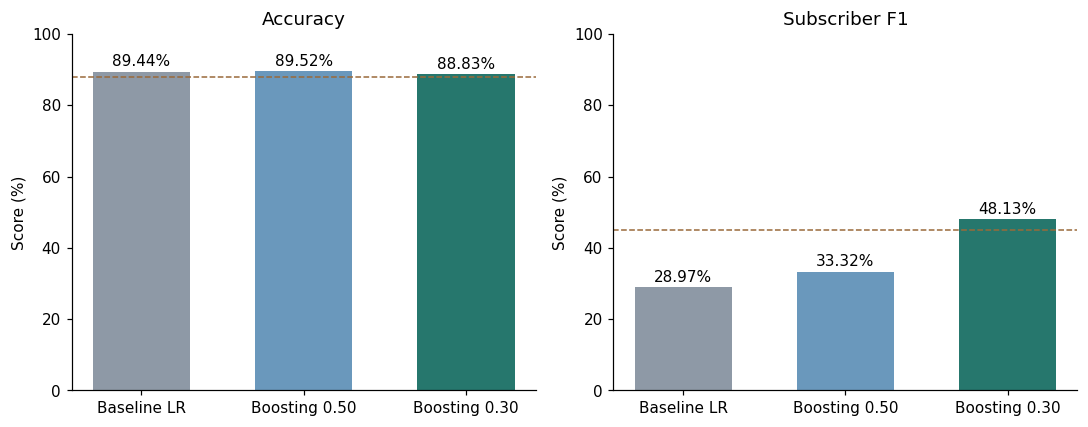

결과 저장 완료: results/, figures/


In [17]:
results_dir = Path('results')
figures_dir = Path('figures')
results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)

final_results.to_csv(results_dir / 'model_comparison.csv', index_label='model')
pd.DataFrame(tune_results).T.to_csv(results_dir / 'tuning_results.csv', index_label='model')
threshold_table.to_csv(results_dir / 'threshold_search.csv', index=False)
cm.to_csv(results_dir / 'confusion_matrix.csv', index_label='actual')

metrics = {
    'model': best_model_name,
    'threshold': best_threshold,
    'train_size': len(y_train),
    'validation_size': len(y_valid),
    'baseline': baseline_scores,
    'final': final_scores,
    'final_boosting_iterations': int(final_model.n_iter_)
}
with open(results_dir / 'metrics.json', 'w', encoding='utf-8') as file:
    json.dump(metrics, file, ensure_ascii=False, indent=2)

labels = ['Baseline LR', 'Boosting 0.50', 'Boosting 0.30']
colors = ['#8e99a6', '#6a98bc', '#26776d']
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, target in zip(axes, ['Accuracy', '가입자 F1'], [88, 45]):
    values = final_results[metric].to_numpy() * 100
    ax.bar(labels, values, color=colors, width=0.6)
    for i, value in enumerate(values):
        ax.text(i, value + 1.5, f'{value:.2f}%', ha='center')
    ax.axhline(target, color='#9a6a3a', linestyle='--', linewidth=1)
    ax.set_title('Accuracy' if metric == 'Accuracy' else 'Subscriber F1')
    ax.set_ylim(0, 100)
    ax.set_ylabel('Score (%)')
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(figures_dir / 'model_comparison.png', dpi=160, bbox_inches='tight')
plt.show()
print('결과 저장 완료: results/, figures/')